In [ ]:
import sympy as sp 
import numpy as np
import matplotlib.pyplot as plt
import math
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

## Equations différentielles ordinaires d'ordre 1
On va ici parler des équation de la forme ${X'(t)} = F({X(t)})$ où $F:\mathbb{X}^n \rightarrow \mathbb{K}^n$ est appellée un champ de vecteur autonome car ne dépendant pas du temps.

On peut parfois écrire une équation différentielle ordinaire d'ordre de p $\in$ $\mathbb{N_+}$ comme une équation d'ordre 1:

$x^{(p)} + a_{p-1}x^{(p-1)} + \dots + a_1 x' + a_0 x = f(x)$ dans certains cas il  existe $F:\mathbb{K}^n \rightarrow \mathbb{K}^n$ telle que ${X'(t)} = F({X(t)})$ .

${X(t)} = \begin{pmatrix} \overset{(1)\hspace{-5pt}}{x} \\ ... \\ \overset{(p-1)\hspace{-5pt}}{x}\end{pmatrix}$


### Equations différentielles affines
Nous allons commencer par traiter les équations différentielles affines du premier ordre de la forme ${X'(t)} = A(t){X(t)} + {B(t)}$  $\small{(1)}$

avec ${A(.)} \in  M_n(\mathbb{K})$ et ${X(t)}, {B(.)} \in \mathbb{K}^n$ 

#### Résolution des équations différentielles linéaires autonomes
Ce sont des cas particulier de $(1)$ où l'application linéaire ${A(.)}$ est constante et ${B(.)}=0$. Dans ce cas particulier là on peut résoudre analytiquement ces équations.

On a l'équation suivante ${X'(t)} = A{X(t)}$. 

Un exemple serait un circuit RLC, 

![photo circuit RLC](https://tse4.mm.bing.net/th/id/OIP.HCWPNtrCG6ROlDbpnH-VlQHaD5?r=0&pid=Api)

l'équation canonique est  $$\frac{d^2 {U_c}}{dt^2} + RC \frac{d {U_c}}{dt} + \frac{1}{LC}{U_c} = 0$$

On a donc la relation suivante $${X'(t)}= \begin{pmatrix} \frac{d{U_c}}{dt} \\ \frac{d²{U_c}}{dt²}  \end{pmatrix} = \begin{pmatrix} 0 & 1 \\ -\frac{1}{LC} & -\frac{R}{L} \end{pmatrix} \begin{pmatrix} {U_c} \\ \frac{d{U_c}}{dt}  \end{pmatrix} $$

On est ici dans un cas particulier où nous sommmes passer d'une équation d'ordre $p$ à une équation d'ordre 1 !

In [3]:
r,c,l =sp.symbols("R,C,L")
t,uc = sp.symbols("t,Uc")
uc0,duc0 = sp.symbols("Uc_0,Uc'")
A = sp.Matrix([[0,1],[-1/(c*l),-r/l ]])
sp.init_printing()




Maintenant on va essayer de résoudre cela en diagonalisant la matrice $A$, ce qu'on va faire c'est un changement de base pour se ramener à une matrice diagonale.

$A = P^{-1} D P$ le système est maintenant équivalent à ${PX'(t)} = DP{X(t)}$ ainsi en posant $ Y(t) = PX(t) \iff Y'(t) = DY(t)$ le système devient très simple à résoudre, en effet les solutions seront : $$Y(t) = \begin{pmatrix} e^{\lambda}y_1(0) \\ e^{\mu}y_1(0)  \end{pmatrix}$$ où $\lambda$ et $\mu$ sont les valeurs propres de $D$

Ensuite il nous restera juste à multiplier $Y(t)$ par la matrice de passage $P^{-1}$

In [5]:
P,D =A.diagonalize()
P_inv =P.inv()

lambd, mu = D[0,0],D[1,1]
#Calcul de y0
y0 = P_inv*sp.Matrix([[uc0],[duc0]])

#Solution dans la base du changement
M = sp.Matrix([[sp.exp(lambd*t),0],[0,sp.exp(mu*t)]])

#Retour dans la base initiale
X = sp.simplify(P*M*y0)
duc = sp.simplify(X[1])
uc = sp.simplify(X[0])

Cas $(\frac{R}{L})² - \frac{4}{LC} > 0$:

la valeur du delta est :  99600000000000.0


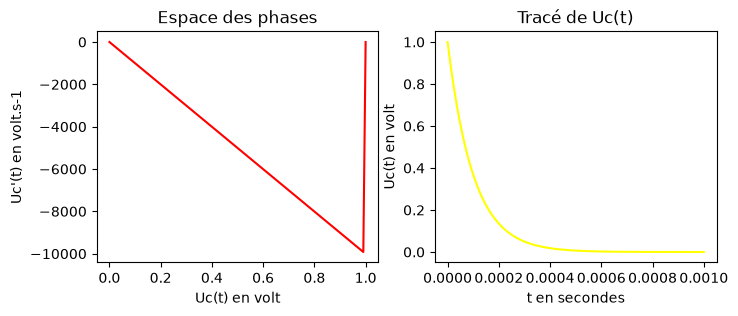

In [ ]:
values = {c:1e-7,l:1e-4,uc0:1,duc0:0,r:1000}
#calculer facteur qualité etc
uc_eval = uc.subs(values)
delta = (r/l)**2 - 4/(l*c)

print("la valeur du delta est : ",delta.subs(values))

time = np.linspace(0,0.001,1000)
uc_t = [sp.re(uc_eval.subs({t:i})) for i in time]


duc_eval = duc.subs(values)
duc_t = [sp.re(duc_eval.subs({t:i})) for i in time]
fig, ax = plt.subplots(nrows=1, ncols=2,figsize= (9,3))
ax[0].set_title("Espace des phases")
ax[0].set_xlabel("Uc(t) en volt")
ax[0].set_ylabel("Uc'(t) en volt.s-1")
ax[0].plot(uc_t,duc_t,color = "red")
ax[1].set_title("Tracé de Uc(t)")
ax[1].set_xlabel("t en secondes")
ax[1].set_ylabel("Uc(t) en volt")
ax[1].plot(time,uc_t, color = "yellow")

Cas $(\frac{R}{L})² - \frac{4}{LC} < 0$:

le delta vaut:  -30000000000.0000


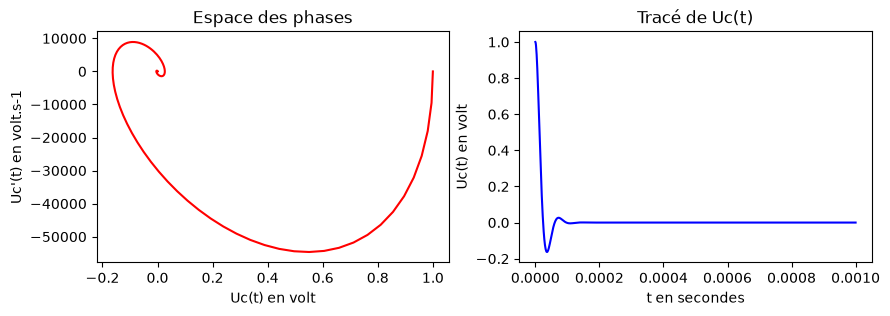

In [ ]:
values = {c:1e-7,l:1e-3,uc0:1,duc0:0,r:100}
uc_eval = uc.subs(values)
delta = (r/l)**2 - 4/(l*c)

print("le delta vaut: ",delta.subs(values))

time = np.linspace(0,0.001,1000)
uc_t = [sp.re(uc_eval.subs({t:i})) for i in time]

duc_eval = duc.subs(values)
duc_t = [sp.re(duc_eval.subs({t:i})) for i in time]

#plot
fig, ax = plt.subplots(nrows=1, ncols=2,figsize= (10,3))
ax[0].set_title("Espace des phases")
ax[0].set_xlabel("Uc(t) en volt")
ax[0].set_ylabel("Uc'(t) en volt.s-1")
ax[0].plot(uc_t,duc_t,color = "red")
ax[1].set_title("Tracé de Uc(t)")
ax[1].set_xlabel("t en secondes")
ax[1].set_ylabel("Uc(t) en volt")
ax[1].plot(time,uc_t, color = "blue")

Cas $(\frac{R}{L})² - \frac{4}{LC} = 0$:


Le delta vaut :  0


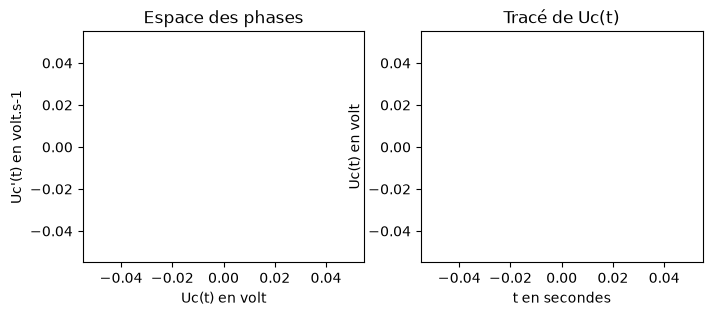

In [ ]:
values = {c:1e-7,l:1e-3,uc0:1,duc0:0,r:2e2}
#calculer facteur qualité etc
uc_eval = uc.subs(values)
delta = (r/l)**2 - 4/(l*c)

print("Le delta vaut : ",delta.subs(values))

time = np.linspace(0,0.001,1000)
uc_t = [sp.re(uc_eval.subs({t:i})) for i in time]
duc_eval = duc.subs(values)
duc_t = [sp.re(duc_eval.subs({t:i})) for i in time]

#Plot
fig, ax = plt.subplots(nrows=1, ncols=2,figsize= (9,3))
ax[0].set_title("Espace des phases")
ax[0].set_xlabel("Uc(t) en volt")
ax[0].set_ylabel("Uc'(t) en volt.s-1")
ax[0].plot(uc_t,duc_t,color = "red")
ax[1].set_title("Tracé de Uc(t)")
ax[1].set_xlabel("t en secondes")
ax[1].set_ylabel("Uc(t) en volt")
ax[1].plot(time,uc_t, color = "blue")

### Equations différentielles autonomes & générales

Retournons à notre cas général, le problème est qu'en général on ne sait pas tout le temps résoudre des équations différentielles. Cependant le champ de vecteurs $F$ lui peut nous fournir des informations qualitatives sur le comportements des solutions. Dans toutes cette partie on va supposer $F$ de classe $\mathcal{C¹}$ ou localement lipschitzienne. 

On a toujours cette équation:

$$ {X'(t)} = F({X(t)}) $$


On va introduire de nouvelles notions comme **le flot**  $\phi: \Omega = \left\{(t,m) \in \mathbb{R} \times U| t \in I_m  \right\}\rightarrow \phi _t(m)$  avec $\phi _t(m)$ la solution maximale associée à l'équation de donnée initiale $X(t_0) = m$ et $I_m$ l'ensemble de définition de la solution maximale. 

On va introduire **l'orbite** $\mathcal{O}_m = \left\{ \phi _t(m)| t \in I_m   \right\}$ qui est l'ensemble des valeurs prises par une solution maximale passant par le point $m$.  
**L'orbite** $\mathcal{O}_m $ peut être **périodique** si il existe $t_0 < t_1$ tels que $\phi _{t_0}(m) = \phi _{t_1}(m)$ **l'orbite** est alors homéomorphe à un cercle. Dans l'autre cas **l'orbite** peut être **non périodique**.

Ce qui nous ammènes au points **stationnaires** qui vérifient $ m \in U$ tel que $F(m) = 0 $ et on a $\mathcal{O}_m = \left\{ m \right\}$. A l'inverse les points **non stationnaires** vérifient $ m \in U$ tel que $F(m) \neq 0 $ son oribite ne contient **aucun point stationnaire** et $\mathcal{O}_m $ est une courbe paramétrique 

Puis pour finir nous allons introduire les **intégrales premières** : $h:U \rightarrow \mathbb{R} $ de classe $\mathcal{C¹}$ telle que la différentielle de h pour tout $m \in U$ soit nulle soit ${D_m}h(X(m)) = 0$.

Un théorème nous dit qu'en dimension n, il faudra n − 1 intégrales premières “indépendantes” pour déterminer de déterminer les orbites qui seront les points $m$ tels que pour tout $i \in [1,n]$,  ${D_m}h_i(X(m)) = 0$



Donnons-nous un exemple en dimension 2 et prenons le cas du système de Lotka Volterra: $$F(x,y) = \begin{pmatrix} x(y-1) \\ y(1-x) \end{pmatrix}$$  
avec $ x,y > 0$


/tmp/ipykernel_39808/701403659.py:7: RuntimeWarning: invalid value encountered in divide
  U_norm = U/norm
/tmp/ipykernel_39808/701403659.py:8: RuntimeWarning: invalid value encountered in divide
  V_norm = V/norm


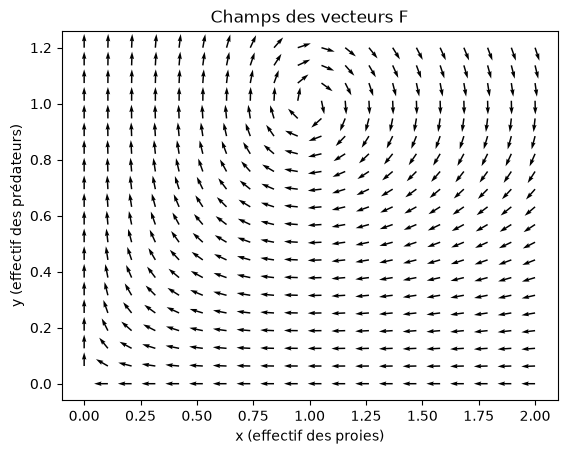

In [ ]:
x = np.linspace(0,2,20)
y = np.linspace(0,1.2,20)
X,Y = np.meshgrid(x,y)
U = X*(Y-1)
V = Y*(1-X)
norm = np.sqrt(U**2+V**2)
U_norm = U/norm
V_norm = V/norm
scale = 1

plt.quiver(X,Y,U_norm*scale, V_norm*scale,color = "black")
plt.title("Champs des vecteurs F")
plt.xlabel("x (effectif des proies)")
plt.ylabel("y (effectif des prédateurs)")
plt.show()

Dans notre cas on va pouvoir déjà commencer par trouver des points stationnaires qui sont en résolvant $\begin{pmatrix} 0 \\ 0 \end{pmatrix}=\begin{pmatrix} x(y-1) \\ y(1-x) \end{pmatrix}$,  les couples $(0,0)$ et $(1,1)$

On peut également montrer que $f(x,y) = ln(y)-y + ln(x)-x$ est une intégrale première du champ F, donc les orbites périodiques sont les ensembles tels que $f(x,y) = a \in \mathbb{R}$, on va pouvoir ainsi les tracer.


### Equations ordinaires différentielles pour la minimisation ###
On veux minimiser:
$$ min_{(x,y) \in \R^2} f(x,y), ~~~~ \text{avec } f(x,y) = x^2 + 2y^2 +xy -2x -4y$$
avec :
- $f \in C^\infty$
- $f$ strictement convexe
- $f$ coercive

Donc le $f$ admet un unique minimiseur sur $\R^2$. Alors ce problème peut être résolu en trouvant la limite de la solution de cette edo:
$$ 
\begin{pmatrix}
x'(t)\\
y'(t)
\end{pmatrix} 
= - \nabla f(x,y)
$$

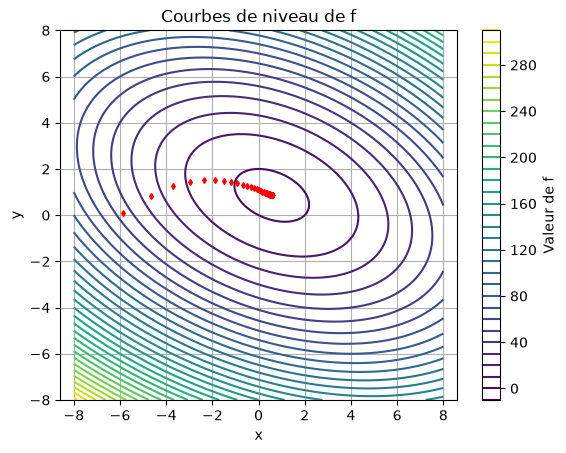

In [4]:
def F(X):
    x,y = X
    return x**2 + 2*y**2 + x*y -2*x -4*y

def gF(X):
    x,y = X
    return np.array([2*x + y -2, 4*y + x - 4])

def Euler2(gF, X0, h, t_max):
    T = t_max//h
    Sx = [] ; Sy = []
    for i in range(int(T)):
        X0 = X0 - h*gF(X0)
        Sx.append(X0[0])
        Sy.append(X0[1])
    return Sx, Sy

X0 = (-6,0)
XX, YY = Euler2(gF, X0, 0.01, 100)

# Création d'une grille de points
x = np.linspace(-8, 8, 200)
y = np.linspace(-8, 8, 200)

X, Y = np.meshgrid(x, y)

# Calcul de f sur la grille
Z = F((X,Y))

# Tracé des courbes de niveau
plt.contour(X, Y, Z, levels=35)

plt.plot(XX[::10], YY[::10], 'd', markersize=3, color='red')

plt.xlabel("x")
plt.ylabel("y")
plt.title("Courbes de niveau de f")
plt.colorbar(label="Valeur de f")
plt.axis("equal")
plt.grid()
plt.show()

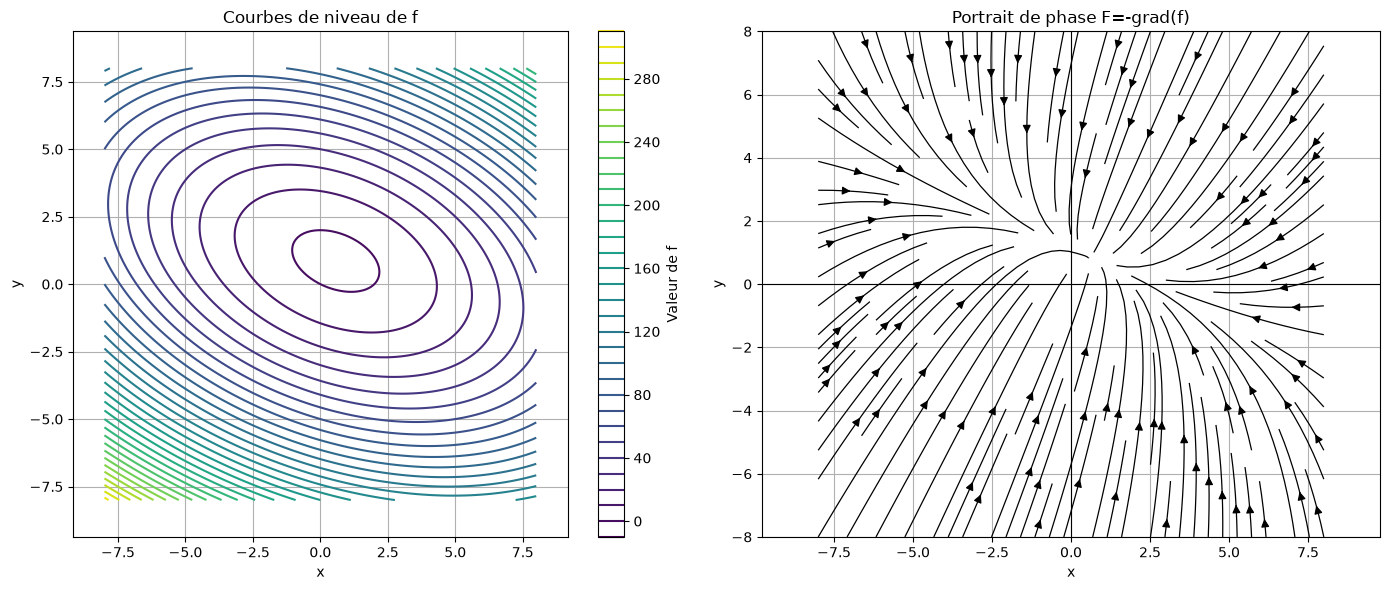

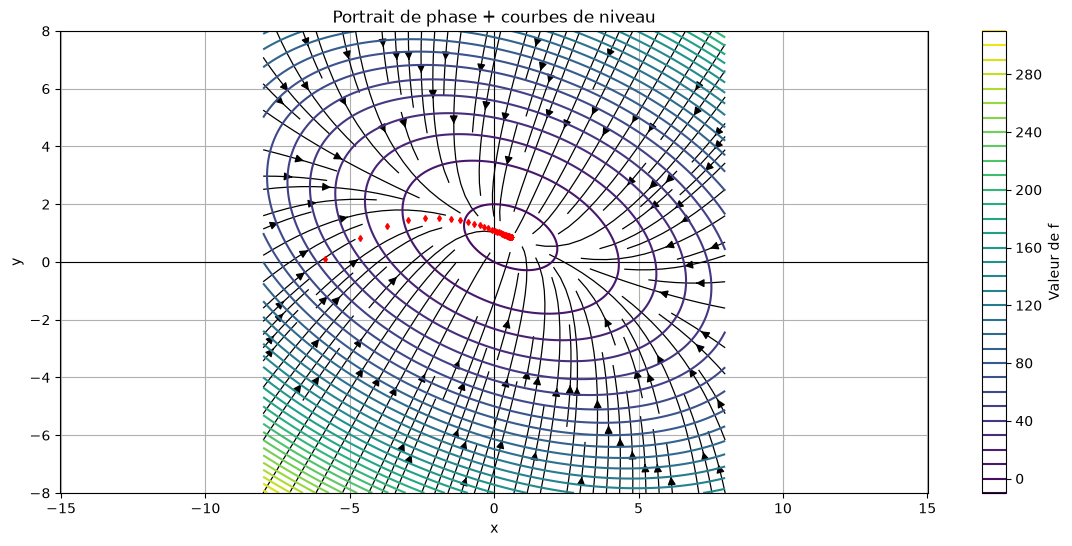

In [7]:
# Fonction pour tracer le portrait de phase
def portraitF(ax, titre):

    # Création de la grille
    x = np.linspace(-8, 8, 800)
    y = np.linspace(-8, 8, 800)
    X, Y = np.meshgrid(x, y)

    # Système différentiel
    U = -(2*X + Y - 2)
    V = -(4*Y + X - 4)

    # Champ de vecteurs
    ax.streamplot(
        X, Y, U, V,
        density=1.2,
        color='black',
        linewidth=0.9,
        arrowsize=1.2
    )

    # Axes
    ax.axhline(0, color='black', linewidth=0.8)
    ax.axvline(0, color='black', linewidth=0.8)

    # Mise en forme
    ax.set_xlim(-8, 8)
    ax.set_ylim(-8, 8)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_title(titre)
    ax.set_aspect('equal')
    ax.grid(False)
    return

# Création de la grille de points
x = np.linspace(-8, 8, 200)
y = np.linspace(-8, 8, 200)
X, Y = np.meshgrid(x, y)

# Calcul de f sur la grille
Z = F((X, Y))


# Création de deux graphiques côte à côte
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Graphique 1 : courbes de niveau ---

# Courbes de niveau
contours = axes[0].contour(X, Y, Z, levels=35, cmap="viridis")

axes[0].set_xlabel("x")
axes[0].set_ylabel("y")
axes[0].axis("equal")
axes[0].grid()
axes[0].set_title("Courbes de niveau de f")
fig.colorbar(contours, ax=axes[0], label="Valeur de f")


# --- Graphique 2 : uniquement le portrait de phase ---

portraitF(axes[1], titre="Portrait de phase F=-grad(f)")

axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].axis("equal")
axes[1].grid()

# Affichage
plt.tight_layout()
plt.show()



# Création du graphiques récapitulatif
fig, axes = plt.subplots(1, 1, figsize=(14, 6))


# --- Graphique  : superposition de toutes les fonctions ---

portraitF(axes, titre="Portrait de phase + courbes de niveau")

# Courbes de niveau
contours = axes.contour(X, Y, Z, levels=35, cmap="viridis")

# Points
axes.set_xlim(-8, 8)
axes.set_ylim(-8, 8)
axes.plot(XX[::10], YY[::10], 'd', markersize=3, color='red')
axes.set_xlabel("x")
axes.set_ylabel("y")
axes.axis("equal")
axes.grid()
fig.colorbar(contours, ax=axes, label="Valeur de f")
plt.show()

On considère le problème:
$$\min_{x\in \R^n} f(x)$$

$\underline{\textbf{Proposition:}}$ Si on suppose que $f$ est coercive, et qu'il existe $\alpha$ et $\beta$ positif tel que:
$$\forall x, \forall \xi \in \R^n:  \beta ||\xi||^2 \ge ~~< D^2f(x)\xi, \xi>~~ \ge \alpha||\xi||^2$$
Alors la solution $x(t)$ du problème de Cauchy:
$$ 
\left\{
\begin{array}{ll}
    \dot{x} = -\nabla f(x) \\
    x(0) = x_0
\end{array}
\right.
$$
converge vers $x^\star$ avec $x^\star$ tel que $f(x^\star) = \min_{x\in \R^n}f(x)$, et de plus la convergence est exponentielle.

## D'un point de vue "Point Fixe ##

On a vu que sous certaine contrainte, résoudre un problème de minimisation est équivalent à la résolution une EDO. Il existe aussi un autre point de vue, basé sur une méthode de point fixe.
En effet, trouver le minimum d'une fonction $f$ revient à trouver $x^\star$ tel que $\nabla f(x^\star) =0$. Cette condition peux alors être réécrite de la manière suivante:
$$ \nabla f(x^\star) =0 \Leftrightarrow x^\star = x^\star - s\nabla f(x^\star) \Leftrightarrow x^\star = T(x^\star)$$
Où $T = I - s\nabla f$. Ainsi, trouver les minimiseurs de $f$ reviens à trouver les points fixes de l'opérateur $T$, et l'aogorithme de gradient peux alors être réécrit comme: $$x_{k+1} = T(x_{k}) $$
Il existe alors la proposition suivante, qui sous certaines conditions, nous garantie la convergence en itérée de notre suite $(x_k)_k$ vers un point fixe de $T$, et donc vers un minimiseur de $f$.

$\underline{\textbf{Proposition:}}$ Soit $T:\R^n \rightarrow \R^n $ un opérateur décroissant, 1-Lipschitz admetant au moins un point fixe: Fix(T) $ \ne \emptyset$. Soit $x_0 \in \R^n$ arbitraire et $(x_k)_k$ une suite défini par $x_{k+1} = T(x_k)$. Supposons de plus que:
$$ ||x_{k+1} - x_k|| \rightarrow 0, k \rightarrow + \infty$$
Alors $(x_k)_k$ converge vers un point fixe de T.

## Chaos ##

Le chaos est une caractéristique intrinsèque d'un système dynamique qui peut être interpreté comme très sensible aux conditions initiales, deux conditions initiales très proches vont donner des solution très différentes.

Le système différentiel le plus célèbre pour illustrer le chaos est le système de Lorenz.
$$ 
\left\{
\begin{array}{ll}
    \frac{dx}{dt} = \sigma(y-x) \\
    \frac{dy}{dt} = x(\rho-z) - y \\
    \frac{dz}{dt} = xy - \beta z
\end{array}
\right.
$$

Avec la méthode d'Euler explicite, ce système se discrétise comme suit:

$$ 
\left\{
\begin{array}{ll}
    (x_0, y_0, z_0) \in \R^3 \\
    x_{k+1} = x_k + h\sigma(y_k-x_k) \\
    y_{k+1} = y_k + h(x_k(\rho-z_k) - y_k) \\
    z_{k+1} = z_k + h(x_ky_k - \beta z_k)
\end{array}
\right.
$$

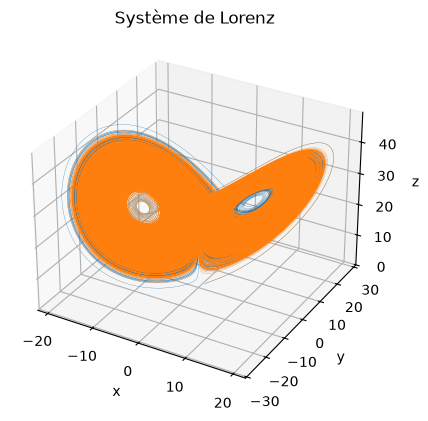

In [10]:
def F_chaos(X, sigma, rho, beta):
    (x,y,z) = X
    return np.array([sigma*(y-x), x*(rho-z)-y, x*y - beta*z])

def Euler3_chaos(F, X0, h, t_max, sigma, rho, beta):
    T = int(t_max//h)
    Sx = np.zeros(T) ; Sy = np.zeros(T) ; Sz = np.zeros(T)
    Sx[0] = X0[0] ; Sy[0] = X0[1] ; Sz[0] = X0[2]
    for i in range(1, T):
        X0 = X0 + h*F(X0, sigma, rho, beta)
        Sx[i] = X0[0]
        Sy[i] = X0[1]
        Sz[i] = X0[2]
    return Sx, Sy, Sz


sigma = 10
rho = 28
beta = 8/3

h = 0.001
t_max = 1000
X0 = np.array([1,1,1])

(XX, YY, ZZ) = Euler3_chaos(F_chaos, X0, h, t_max, sigma, rho, beta)
(XX1, YY1, ZZ1) = Euler3_chaos(F_chaos, X0+np.array([0.00001,0,0]), h, t_max, sigma, rho, beta)

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

ax.plot(XX, YY, ZZ, linewidth=0.2)
ax.plot(XX1, YY1, ZZ1, linewidth=0.2)
ax.set_title("Système de Lorenz")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

plt.show()

In [ ]:
# Paramètres
sigma = 10
rho = 28
beta = 8/3

h = 0.001
N = 20000

# Euler
X = np.zeros((N, 3))
X[0] = [1, 1, 1]

for i in range(N-1):
    x, y, z = X[i]

    X[i+1] = [
        x + h*sigma*(y-x),
        y + h*(x*(rho-z)-y),
        z + h*(x*y-beta*z)
    ]

# On réduit le nombre d'images
indices = np.linspace(0, N-1, 100, dtype=int)

# Figure
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection='3d')

ax.set_xlim(-25, 25)
ax.set_ylim(-35, 35)
ax.set_zlim(0, 55)

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title("Attracteur de Lorenz")

line, = ax.plot([], [], [], lw=0.5)

def init():
    line.set_data([], [])
    line.set_3d_properties([])
    return line,

def update(k):
    i = indices[k]

    line.set_data(X[:i+1, 0], X[:i+1, 1])
    line.set_3d_properties(X[:i+1, 2])

    return line,

ani = FuncAnimation(
    fig,
    update,
    frames=len(indices),
    init_func=init,
    interval=30,
    blit=False,
    repeat=False
)

# Affichage
plt.close(fig)

display(HTML(ani.to_jshtml()))

## Etude de différents schémas numériques

Cette partie traite de l'étude de différents schéma numérique, notamment sur leur ordre. Pour ce faire, on considère trois schémas: Euler explicite, Adams Bashforth et Runge-Kutta 4.

Pour comparer leurs ordre de convergence, on va considérer une EDO simple que l'on sait résoudre, et ensuite comparer l'erreur entre la solution exacte et la solution approché par le schéma considéré.
On cosidère pour ce faire, l'EDO:
$$ 
\left\{
\begin{array}{ll}
    x'(t) = -x(t) \\
    x_0 = 1
\end{array}
\right.
$$
Dont la solution exacte est donné par:
$$ x(t) = \exp(-t)$$

### Pour la méthode d'Euler ###

La méthode d'Euler est une méthode d'ordre 1 qui consiste en partant de $x(t_0) = x_0$ à itérer successivement sur une subdivision de $[t_0,t_N]$:  
$~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~$ $\forall n \in [1,N], ~ x_{n+1} = x_{n} + h_n \times f(x_n,t_n)$ avec $h_n = t_{n+1} - t_{n}$

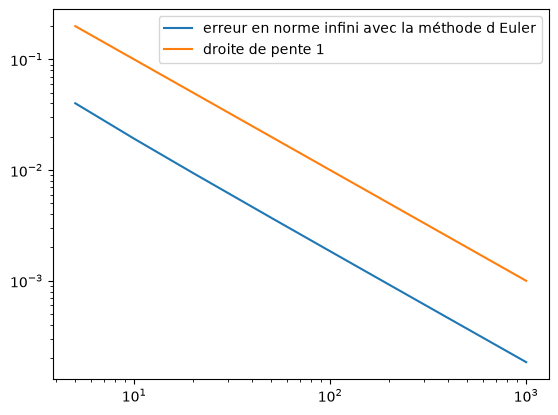

In [11]:
def solution_exacte(N):
    solution = np.zeros(N+1)
    xx = np.linspace(0, 1, N+1)
    for n in range(N+1):
        solution[n] = math.exp(-xx[n])
    return solution

def f(t, x):
    return -x

def EE(f, t0, tf, eta, N):
    h = (tf - t0) / N
    xtab = np.zeros(N+1)
    xtab[0] = eta
    for n in range(1,N+1):
        t_n = t0 + (n-1)*h
        xtab[n] = xtab[n-1] + h*f(t_n, xtab[n-1])
    return xtab

#print(EE(f, 0, 1, 1, 10))
    
erreur1 = []
ordre1 = []
x = [5, 10,20,50,100,200,300,500,750,1000]
for n in x:
    erreur1.append(np.max(abs((solution_exacte(n) - (EE(f, 0, 1, 1, n))))))
    ordre1.append(1/n)
    
    
plt.figure()
plt.loglog(x, erreur1, label = 'erreur en norme infini avec la méthode d Euler')
plt.loglog(x, ordre1, label = 'droite de pente 1')
plt.legend()
plt.show()

Inteprétation ?

### Pour la méthode Adam Bashford ### 

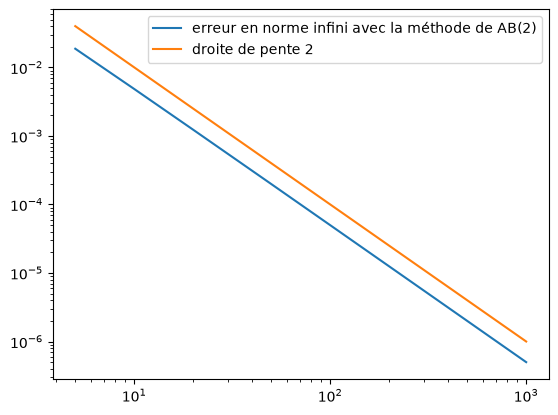

In [12]:
def AB2(f, t0, tf, eta, N):
    h = (tf - t0) / N
    xtab = np.zeros(N+1)
    xtab[0] = eta
    xtab[1] = xtab[0] + h*f(t0, xtab[0])
    for n in range(2,N+1):
        xtab[n] = xtab[n-1] + (h/2)*(3*f(t0 + (n-1)*h, xtab[n-1]) - f(t0 + (n-2)*h, xtab[n-2]))
    return xtab

#print(AB2(f, 0, 1, 1, 10))

erreur2 = []
ordre2 = []
x = [5, 10,20,50,100,200,300,500,750,1000]
for n in x:
    erreur2.append(np.max(abs((solution_exacte(n) - (AB2(f, 0, 1, 1, n))))))
    ordre2.append(((1-0)/n)**2)
    
    
plt.figure()
plt.loglog(x, erreur2, label = 'erreur en norme infini avec la méthode de AB(2)')
plt.loglog(x, ordre2, label = 'droite de pente 2')
plt.legend()
plt.show()

## Annexes ##

### Preuves ###

#### Preuve de la proposition suivante ####

$\underline{\textbf{Proposition:}}$ Si on suppose que $f$ est coercive, et qu'il existe $\alpha$ et $\beta$ positif tel que:
$$\forall x, \forall \xi \in \R^n:  \beta ||\xi||^2 \ge ~~< D^2f(x)\xi, \xi>~~ \ge \alpha||\xi||^2$$
Alors la solution $x(t)$ du problème de Cauchy:
$$ 
\left\{
\begin{array}{ll}
    \dot{x} = -\nabla f(x) \\
    x(0) = x_0
\end{array}
\right.
$$
converge vers $x^\star$ avec $x^\star$ tel que $f(x^\star) = \min_{x\in \R^n}f(x)$, et de plus la convergence est exponentielle.


Pour comencer, l'hypothèse sur $D^2f$ implique: $f \mapsto \nabla f$ est globalement lipschitzienne:
$$
|\nabla f(x) - \nabla f(y)| = \int^1_0 D^2f(y+\sigma (x-y))d\sigma \cdot (x-y) \leq \beta|x-y|
$$
Donc on a l'existence et l'unicité de la solution $x(t)$ à notre problème de Cauchy.

De plus, on pose $y(t) = x(t) - x^\star$, alors $\dot{y} = -\nabla f(y + x^\star)$. On a ensuite:
$$
\begin{align*}
 &\dot{y}y = -\nabla f(y + x^\star)\cdot y \\
 & = -(\nabla f(y + x^\star) -\nabla f(x^\star))y \\
 &\leq -\alpha|y|^2
\end{align*}
$$

De plus, $\frac{d}{dt}|y|^2 = \frac{d}{dt}(y\cdot y) = 2\dot{y}y $, on a ainsi:

$$
\begin{align*}
 &\frac{1}{2} \frac{d}{dt}|y|^2 + \alpha |y|^2 \leq 0\\
 &\Leftrightarrow \frac{d}{dt}|y|^2 + 2\alpha |y|^2 \leq 0\\
 &\Leftrightarrow \frac{d}{dt}( e^{2\alpha t} |y^2|) \leq 0 \\
 &\Leftrightarrow |y(t)|^2 \leq |y(0)|^2 e^{-2\alpha t} \\
 &\Leftrightarrow |y(t)|^2 \leq |x_0 - x^\star|^2 e^{-2\alpha t}
\end{align*}
$$

Soit $|x(t)-x^\star| \leq |x_0 - x^\star| e^{-\alpha t}$

$$~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~\square$$

### $\underline{\textbf{Etude du Schéma Adams-Bashfort 2}}$ ###
Dans cette partie, nous proposons d'étudier le schéma d'Adams-Bashfort 2 défini de la manière suivante.

Pour un problème du type:
$$x'(t) = f(t,x) ~~~~, \forall t \in \R^+$$
le schéma est le suivant:
$$x_{n+2} = x_{n+1} + \frac{h}{2} ( 3f_{n+1} - f_n) $$

Dans ce chapitre, nous allons alors étudier théoriquement ce schéma pour vérifier si il converge bien, quelle est son ordre de convergence, et même trouver une borne majorant l'erreur entre la solution exacte $x(t_n)$ et la solution approchée $x_n$

Commençons par étudier la consistance de celui-ci.

### $\underline{\textbf{Étude de la convergence}}$ ###
#### $\textbf{Étude de la consistance}$ ####

Pour commencer, on applique notre schéma à la solution exacte $x$ de notre équation, ce qui donne:
$$x(t_{n+2}) -  x(t_{n+1}) - \frac{h}{2}(3f(t_{n+1}) - f(t_{n})) = 0$$
On effectue ensuite un développement de Taylor sur les termes $x(t_{n+2}), x(t_{n+1}), f(t_{n+1})$. On trouve alors:

\begin{align*}
    x(t_{n+2}) = x(t_{n} + 2h) = x(t_{n}) + 2hx'(t_{n}) + \frac{4h^2}{2}x''(t_n) + \frac{8h^3}{6}x^{(3)}(t_n) + O(h^4) \\
    x(t_{n+1}) = x(t_{n} + h) = x(t_{n}) + hx'(t_{n}) + \frac{h^2}{2}x''(t_n) + \frac{h^3}{6}x^{(3)}(t_n) + O(h^4) \\
    f(t_{n+1}) = x'(t_{n+1}) = x'(t_{n} + h) = x'(t_{n}) + hx''(t_{n}) + \frac{h^2}{2}x^{(3)}(t_n) + O(h^3) \\
\end{align*}

On peut maintenant réécrire le schéma en y insérant ces décompositions.
\begin{align*}
        &x(t_{n+2}) -  x(t_{n+1}) - \frac{h}{2}(3f(t_{n+1}) - f(t_{n}))\\
        &= x(t_n) - x(t_n)\\
        &+ 2hx'(t_n) - hx'(t_n) - \frac{3h}{2}x'(t_n)\\
        &+ 2h^2x''(t_n) - \frac{h^2}{2}x''(t_n) \frac{3h^2}{2}x''(t_n)\\
        & + \frac{4h^3}{3}x^{(3)}(t_n) - \frac{h^3}{6}x^{(3)}(t_n) - \frac{3h^3}{4}x^{(3)}(t_n) + O(h^4)\\
        &=\frac{4h^3}{3}x^{(3)}(t_n) - \frac{h^3}{6}x^{(3)}(t_n) - \frac{3h^3}{4}x^{(3)}(t_n) + O(h^4)\\
        &=O(h^3)
\end{align*}

On vient ainsi de montrer que notre schéma est consistant d'ordre $2$.

### $\textbf{Étude de la zéro-stabilité}$ ###

Considérons une méthode multipas à 2 niveaux sous sa forme générale:
$$x_{n+2} + \alpha_0 x_{n+1} + \alpha_1x_{n}= h(\beta_2 f_{n+2} + \beta_1 f_{n+1} + \beta_0 f_{n})$$
Nous définissons le premier et le second polynôme caractéristique de cette méthode par:

$\underline{\textbf{définition:}}$
    Les premier et deuxième polynômes caractéristiques d’une méthode multipas à 2 niveaux sont définis par
$$\rho(r) = r^2 + \alpha_1r + \alpha_0 \text{~~~~~~et~~~~~~~~} \sigma(r) = \beta_2r^2 + \beta_1r + \beta_0$$
respectivement.


Donc dans notre cas, pour la méthode d'Adams-Bashfort 2, le premier polynôme caractéristique est défini par:
$$ \rho(r) = r^2 - r$$

Nous définissons en plus, la condition des racines:

$\underline{\textbf{définition:}}$
Un polynôme est dit satisfaire la condition de racines si toutes ses racines sont
incluses dans $\bar{B}(0; 1)$, les racines sur la frontière étant simples. Donc, pour toutes racines r, $|r| \leq 1$ et si $|r| = 1$, la racine est simple.


$\underline{\textbf{proposition:}}$
    Une méthode multipas est dite zéro-stable si son premier polynôme caractéristique
    $\rho(r)$ satisfait la condition de racines.


Dans notre cas, on a bien évidemment que le premier polynôme caractéristique $\rho(r)$ vérifie la condition des racines, en effet:
\begin{align*}
        &\rho(r) = 0\\
        &\Leftrightarrow r^2 - r = 0\\
        &\Leftrightarrow r = 1 \text{~~~~ou~~~~} r = -1
\end{align*}
Notre schéma est donc zéro-stable par la proposition précédente.

Et enfin, nous pouvons conclure de la convergence de notre schéma numérique par le théorème suivant.

$\underline{\textbf{théorème:}}$
    Dahlquist 1956. Une méthode multipas est convergente si et seulement si elle est
consistante et (zero)-stable.



### $\textbf{Étude de l'erreur du schéma}$ ###

Dans cette section, l'objectif est d'étudier l'erreur commise entre la solution exacte du schéma $x(t_n)$ et la solution approchée $x_n$. Pour ce faire, on définit l'erreur:
$$e_n = x(t_n) - x_n,$$
on suppose de plus que dans notre problème, $f$ est lipschitzienne, et on note $||f||_{lip}$ sa constante de Lipschitz.
On a alors:

\begin{align*}
        &e_{n+2} = x(t_{n+2}) - x_{n+2}\\
        &=x(t_{n+1}) - x_{n+1} - \frac{h}{2}(3f(t_{n+1},x_{n+1}) - 3f_{n+1}) - \frac{h}{2}(f(t_{n},x_{n}) - f_{n}) + h^3\sup|x^{(3)}|\\
\end{align*}
D'où
\begin{align*}
        &|e_{n+2}|=|x(t_{n+1}) - x_{n+1} - \frac{h}{2}(3f(t_{n+1},x_{n+1}) - 3f_{n+1}) - \frac{h}{2}(f(t_{n},x_{n}) - f_{n}) + h^3\sup|x^{(3)}|~~|\\
        &\le |e_{n+1}| + \frac{3h}{2}|f(t_{n+1},x_{n+1}) - f_{n+1})| + \frac{h}{2}|f(t_{n},x_{n}) - f_{n})|+ h^3\sup|x^{(3)}|\\
        &\le |e_{n+1}| + \frac{3||f||_{lip}h}{2}|e_{n+1}| + \frac{||f||_{lip}h}{2}|e_{n}|+ h^3\sup|x^{(3)}|\\
\end{align*}

Nous avons ainsi une relation de récurrence d'ordre $2$. Cependant, pour se faciliter le travail, on note:
$$E_n = \max(|e_{n+1}|, |e_{n}|)$$
on peut réécrire alors l'inégalité précédente par:
\begin{align*}
        &|e_{n+2}| \le |e_{n+1}| + \frac{3||f||_{lip}h}{2}|e_{n+1}| + \frac{||f||_{lip}h}{2}|e_{n}|+ h^3\sup|x^{(3)}|\\
        &\le E_n + \frac{3||f||_{lip}h}{2}E_n + \frac{||f||_{lip}h}{2}E_n+ h^3\sup|x^{(3)}|\\
        &\le (1+2h||f||_{lip})E_n + h^3\sup|x^{(3)}|\\
        &\le (1+2h||f||_{lip})^{n+1}E_0 + \frac{(1+2h||f||_{lip})^{n+1} - 1}{2h||f||_{lip}}h^3\sup|x^{(3)}|
\end{align*}
Ou encore $E_{n+1}\le(1+2h||f||_{lip})^{n+1}E_0 + \frac{(1+2h||f||_{lip})^{n+1} - 1}{2h||f||_{lip}}h^3\sup|x^{(3)}|$.
Et enfin, en remarquant aussi que $n\le \frac{T}{h}$, et que $E_0 = O(h^2)$ on obtient finalement:
\begin{align*}
        &E_{n} \le e^{2T||f||_{lip}}E_0 + \frac{e^{2T||f||_{lip}}}{2||f||_{lip}}h^2\sup|x^{(3)}|\\
        &\le \frac{e^{2T||f||_{lip}}}{||f||_{lip}}Ch^2\sup|x^{(3)}|\\
\end{align*}

Et on retrouve enfin que $E_n = O(h^2)$